# 04 - Adding club strength

The first model (notebook 03) ignored the club. Its biggest misses were exactly where the club matters: players at big clubs were underestimated, players at small clubs overestimated.

This notebook adds one feature, **club points per game in 2025/26**, built from real match results (`games.csv`).
It is *not* built from market values, so it does not leak the answer into the features.

Plan:
1. Build a 2025/26 Premier League table from match results
2. Give every player the strength of their club (weighted by minutes if they moved mid-season)
3. Re-run the same models with and without the club feature, on the same train/test split
4. Check whether the biggest misses from notebook 03 got better

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, NullFormatter

from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict, KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")
FIG = Path("../figures"); FIG.mkdir(exist_ok=True)

LEAGUE = "GB1"
SEASON_START = pd.Timestamp("2025-07-01"); SEASON_END = pd.Timestamp("2026-06-30")

# Same chart styling as notebook 03
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE = "#2a78d6"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True, "font.size": 10, "axes.titlesize": 12,
    "axes.titleweight": "regular", "axes.titlelocation": "left",
})

need = ["games.csv", "appearances.csv", "clubs.csv", "players.csv"]
missing = [f for f in need if not (RAW / f).exists()]
assert not missing, f"Missing in data/raw: {missing} (unzip the full Kaggle archive there)"

df = pd.read_csv(PROCESSED / "PL_2025_26_model_data.csv")
df["log_value"] = np.log(df["market_value"])
print(df.shape)

(400, 15)


## 1. A 2025/26 Premier League table, built from match results

In [2]:
games = pd.read_csv(
    RAW / "games.csv",
    usecols=["game_id", "competition_id", "date", "home_club_id", "away_club_id", "home_club_goals", "away_club_goals"],
    parse_dates=["date"],
)
games = games[(games["competition_id"] == LEAGUE) & games["date"].between(SEASON_START, SEASON_END)]
games = games.dropna(subset=["home_club_goals", "away_club_goals"])
print(len(games), "played Premier League games in 2025/26 (a full season has 380)")

# one row per club per game, from that club's point of view
home = games.rename(columns={"home_club_id": "club_id", "home_club_goals": "gf", "away_club_goals": "ga"})[["club_id", "gf", "ga"]]
away = games.rename(columns={"away_club_id": "club_id", "away_club_goals": "gf", "home_club_goals": "ga"})[["club_id", "gf", "ga"]]
long = pd.concat([home, away])
long["points"] = np.select([long["gf"] > long["ga"], long["gf"] == long["ga"]], [3, 1], default=0)

club = long.groupby("club_id").agg(played=("points", "size"), points=("points", "sum"), gf=("gf", "sum"), ga=("ga", "sum"))
club["club_ppg"] = club["points"] / club["played"]
club["club_gd_per_game"] = (club["gf"] - club["ga"]) / club["played"]

names = pd.read_csv(RAW / "clubs.csv", usecols=["club_id", "name"]).rename(columns={"name": "club"})
club = club.reset_index().merge(names, on="club_id", how="left").sort_values(["points", "club_gd_per_game"], ascending=False).reset_index(drop=True)
club.index = club.index + 1
print(len(club), "clubs")
club[["club", "played", "points", "gf", "ga", "club_ppg"]].round(2)

380 played Premier League games in 2025/26 (a full season has 380)
20 clubs


,club,played,points,gf,ga,club_ppg
1,Arsenal FC,38,85,71,27,2.24
2,Manchester City,38,78,77,35,2.05
3,Manchester United,38,71,69,50,1.87
4,Aston Villa,38,65,56,49,1.71
5,Liverpool FC,38,60,63,53,1.58
6,AFC Bournemouth,38,57,58,54,1.50
7,Sunderland AFC,38,54,42,48,1.42
8,Brighton & Hove Albion,38,53,52,46,1.39
9,Brentford FC,38,53,55,52,1.39
10,Chelsea FC,38,52,58,52,1.37


**Sanity check:** compare this table with the real 2025/26 Premier League final table (points and order). If it matches, the feature is built correctly.

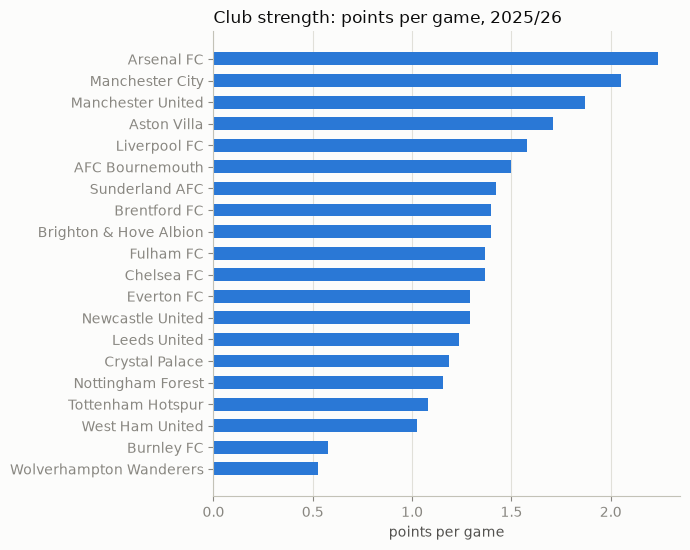

In [3]:
order = club.sort_values("club_ppg")
fig, ax = plt.subplots(figsize=(7, 5.6))
ax.barh(order["club"], order["club_ppg"], color=BLUE, height=0.6)
ax.set_title("Club strength: points per game, 2025/26")
ax.set_xlabel("points per game")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "06_club_points_per_game.png", dpi=200, bbox_inches="tight")
plt.show()

## 2. Give every player their club's strength

A player's club is taken from their appearances (`player_club_id`), not from the current club in the player file, because the snapshot is from July 2026 and some players have already moved. A player who changed clubs mid-season gets the minutes-weighted average of his clubs.

In [4]:
app = pd.read_csv(
    RAW / "appearances.csv",
    usecols=["player_id", "player_club_id", "date", "competition_id", "minutes_played"],
    parse_dates=["date"],
)
app = app[(app["competition_id"] == LEAGUE) & app["date"].between(SEASON_START, SEASON_END)]
app = app.merge(club[["club_id", "club_ppg", "club_gd_per_game"]], left_on="player_club_id", right_on="club_id", how="left")

app["w_ppg"] = app["minutes_played"] * app["club_ppg"]
app["w_gd"] = app["minutes_played"] * app["club_gd_per_game"]
per_player = app.groupby("player_id").agg(m=("minutes_played", "sum"), w_ppg=("w_ppg", "sum"), w_gd=("w_gd", "sum"),
                                          n_clubs=("player_club_id", "nunique"))
per_player["club_ppg"] = per_player["w_ppg"] / per_player["m"]
per_player["club_gd_per_game"] = per_player["w_gd"] / per_player["m"]

df = df.merge(per_player[["club_ppg", "club_gd_per_game", "n_clubs"]], left_on="player_id", right_index=True, how="left")
print("players without a club feature:", int(df["club_ppg"].isna().sum()))
print("players who played for 2+ Premier League clubs this season:", int((df["n_clubs"] > 1).sum()))
df[["name", "current_club_name", "club_ppg", "club_gd_per_game"]].sample(6, random_state=1).round(2)

players without a club feature: 0
players who played for 2+ Premier League clubs this season: 9


,name,current_club_name,club_ppg,club_gd_per_game
398,El Hadji Malick Diouf,West Ham United,1.03,-0.50
125,Lucas Perri,Leeds United,1.24,-0.18
328,Tim Iroegbunam,Everton FC,1.29,-0.08
339,Antonín Kinský,Tottenham Hotspur,1.08,-0.24
172,Nikola Milenković,Nottingham Forest,1.16,-0.08
342,Tyrick Mitchell,Crystal Palace,1.18,-0.26


In [5]:
print("corr(club_ppg, club_gd_per_game):", round(df["club_ppg"].corr(df["club_gd_per_game"]), 2), "(they carry almost the same information, so only points per game is used)")
print("corr(club_ppg, log value):       ", round(df["club_ppg"].corr(df["log_value"]), 2))
print("corr(age, log value) for comparison:", round(df["age"].corr(df["log_value"]), 2))

corr(club_ppg, club_gd_per_game): 0.97 (they carry almost the same information, so only points per game is used)
corr(club_ppg, log value):        0.38
corr(age, log value) for comparison: -0.65


## 3. Same models, with and without the club feature

Same 80/20 split (`random_state=42`) and same 5-fold cross-validation as notebook 03, so the only difference between the rows is the club feature.

In [6]:
df["age_sq"] = df["age"] ** 2
base_num = ["age", "age_sq", "minutes", "goals_per90", "assists_per90", "international_caps", "contract_years_left"]
club_num = base_num + ["club_ppg"]
cat = ["position"]
y = df["log_value"]
train_idx, test_idx = train_test_split(df.index, test_size=0.2, random_state=42)

def make(model, num):
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat),
    ])
    return Pipeline([("prep", prep), ("model", model)])

def lin(): return LinearRegression()
def rf():  return RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)
def avg(): return DummyRegressor()

def evaluate(name, factory, num):
    X = df[num + cat]
    pipe = make(factory(), num).fit(X.loc[train_idx], y.loc[train_idx])
    pred = pipe.predict(X.loc[test_idx])
    cv = cross_val_score(make(factory(), num), X, y, cv=KFold(5, shuffle=True, random_state=42), scoring="r2")
    actual = np.exp(y.loc[test_idx])
    return {
        "model": name,
        "R² (test, log value)": round(r2_score(y.loc[test_idx], pred), 3),
        "R² (5-fold CV)": round(cv.mean(), 3),
        "MAE (test, €M)": round(mean_absolute_error(actual, np.exp(pred)) / 1e6, 2),
        "median abs % error": round(float(np.median(np.abs(np.exp(pred) / actual - 1))) * 100, 1),
    }

results = pd.DataFrame([
    evaluate("Baseline (predict the average)", avg, base_num),
    evaluate("Linear regression, no club (v1)", lin, base_num),
    evaluate("Linear regression + club (v2)", lin, club_num),
    evaluate("Random forest, no club", rf, base_num),
    evaluate("Random forest + club", rf, club_num),
]).set_index("model")
results

,"R² (test, log value)",R² (5-fold CV),"MAE (test, €M)",median abs % error
model,,,,
Baseline (predict the average),-0.039,-0.026,13.68,41.3
"Linear regression, no club (v1)",0.672,0.728,9.03,31.2
Linear regression + club (v2),0.766,0.809,7.33,31.2
"Random forest, no club",0.682,0.699,9.03,29.8
Random forest + club,0.775,0.792,7.04,23.5


In [7]:
v1, v2 = results.loc["Linear regression, no club (v1)"], results.loc["Linear regression + club (v2)"]
print(f"Linear regression: R² (CV) {v1['R² (5-fold CV)']} -> {v2['R² (5-fold CV)']}, "
      f"R² (test) {v1['R² (test, log value)']} -> {v2['R² (test, log value)']}")
print(f"                   MAE €{v1['MAE (test, €M)']}M -> €{v2['MAE (test, €M)']}M, "
      f"median error {v1['median abs % error']}% -> {v2['median abs % error']}%")
results.to_csv(FIG / "model_comparison.csv")

Linear regression: R² (CV) 0.728 -> 0.809, R² (test) 0.672 -> 0.766
                   MAE €9.03M -> €7.33M, median error 31.2% -> 31.2%


**How to read this:** with only 80 test players, small differences (about 0.01 in R²) are noise. Trust the 5-fold CV column and the direction across rows more than any single number. If the club feature helps only a little, that is also a finding: it means the remaining error comes from something else (brand, position-specific stats, injuries, transfer rumours).

In [8]:
lin2 = make(LinearRegression(), club_num).fit(df[club_num + cat], y)     # fit on all players, for interpretation only
coefs = pd.Series(lin2.named_steps["model"].coef_,
                  index=[n.split("__")[1] for n in lin2.named_steps["prep"].get_feature_names_out()])
print("Standardized effect on log value of +1 standard deviation:")
coefs.drop(["age", "age_sq"]).filter(regex="^(?!position_)").sort_values(ascending=False).round(3).to_frame("coefficient")

Standardized effect on log value of +1 standard deviation:


,coefficient
club_ppg,0.300
minutes,0.272
goals_per90,0.142
contract_years_left,0.136
international_caps,0.128
assists_per90,0.028


## 4. Did the club feature fix the biggest misses?

Out-of-sample predictions for every player, for the model without (v1) and with (v2) the club feature. The chart takes the 8 players the v1 model missed by the most (4 too high, 4 too low) and shows where v2 puts them. 1x means the model matches Transfermarkt exactly.

In [9]:
def oof_ratio(num):
    pred = np.exp(cross_val_predict(make(LinearRegression(), num), df[num + cat], y, cv=KFold(5, shuffle=True, random_state=42)))
    return pred / df["market_value"]

cmp = df[["name", "current_club_name", "position", "age", "market_value", "club_ppg"]].copy()
cmp["ratio_v1"] = oof_ratio(base_num)
cmp["ratio_v2"] = oof_ratio(club_num)

pick = pd.concat([cmp.nlargest(4, "ratio_v1"), cmp.nsmallest(4, "ratio_v1")]).sort_values("ratio_v1")
closer = (np.abs(np.log(pick["ratio_v2"])) < np.abs(np.log(pick["ratio_v1"]))).sum()
print(f"{closer} of these 8 players moved closer to Transfermarkt with the club feature")

mean_miss_v1 = np.abs(np.log(cmp["ratio_v1"])).mean()
mean_miss_v2 = np.abs(np.log(cmp["ratio_v2"])).mean()
print(f"Across all {len(cmp)} players, the typical miss (mean |log ratio|) went {mean_miss_v1:.3f} -> {mean_miss_v2:.3f}")

pick[["name", "current_club_name", "position", "age", "market_value", "club_ppg", "ratio_v1", "ratio_v2"]].round(2)

6 of these 8 players moved closer to Transfermarkt with the club feature
Across all 400 players, the typical miss (mean |log ratio|) went 0.415 -> 0.346


,name,current_club_name,position,age,market_value,club_ppg,ratio_v1,ratio_v2
0,James Milner,Brighton & Hove Albion,Midfield,40.41,500000,1.39,0.11,0.15
133,Rodri,Manchester City,Midfield,29.95,50000000,2.05,0.23,0.40
224,Lisandro Martínez,Manchester United,Defender,28.37,40000000,1.87,0.26,0.39
107,Ben White,Arsenal FC,Defender,28.65,30000000,2.24,0.30,0.59
78,Luke O'Nien,Sunderland AFC,Defender,31.53,700000,1.42,4.87,5.45
277,Armando Broja,Burnley FC,Attack,24.73,5000000,0.58,5.05,3.14
24,Idrissa Gueye,Everton FC,Midfield,36.68,500000,1.29,6.43,4.92
11,Karl Darlow,Leeds United,Goalkeeper,35.65,200000,1.24,8.27,8.51


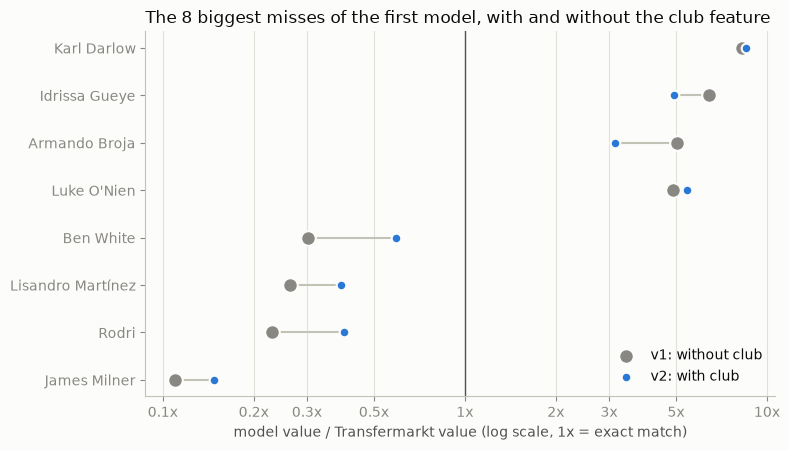

In [10]:
GREY = MUTED
fig, ax = plt.subplots(figsize=(8, 4.6))
ypos = np.arange(len(pick))
ax.hlines(ypos, pick["ratio_v1"], pick["ratio_v2"], color=AXIS, linewidth=1.5, zorder=2)
ax.scatter(pick["ratio_v1"], ypos, s=110, color=GREY, edgecolor=SURFACE, linewidth=1.5, zorder=3, label="v1: without club")
ax.scatter(pick["ratio_v2"], ypos, s=48, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=4, label="v2: with club")
ax.axvline(1, color=INK2, linewidth=1, zorder=1)

ax.set_xscale("log")
lo = min(pick["ratio_v1"].min(), pick["ratio_v2"].min()) * 0.8
hi = max(pick["ratio_v1"].max(), pick["ratio_v2"].max()) * 1.25
ax.set_xlim(lo, hi)
ticks = [t for t in [0.1, 0.2, 0.3, 0.5, 1, 2, 3, 5, 10] if lo <= t <= hi]
ax.set_xticks(ticks); ax.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}x"))
ax.xaxis.set_minor_formatter(NullFormatter()); ax.minorticks_off()

ax.set_yticks(ypos); ax.set_yticklabels(pick["name"])
ax.grid(axis="y", visible=False)
ax.set_xlabel("model value / Transfermarkt value (log scale, 1x = exact match)")
ax.set_title("The 8 biggest misses of the first model, with and without the club feature")
ax.legend(frameon=False, loc="lower right")
fig.tight_layout()
fig.savefig(FIG / "07_club_feature_effect.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Save the version 2 dataset

In [11]:
out_cols = [c for c in df.columns if c not in ("log_value", "age_sq", "n_clubs")]
df[out_cols].to_csv(PROCESSED / "PL_2025_26_model_data_v2.csv", index=False)
print("saved", PROCESSED / "PL_2025_26_model_data_v2.csv", df[out_cols].shape)

saved ../data/processed/PL_2025_26_model_data_v2.csv (400, 16)


## What to say in the presentation

- Notebook 03's biggest misses followed the club: big-club players underestimated, small-club players overestimated.
- Fix tried: one club feature (points per game from match results, not from market values, to avoid leakage).
- Result: the table in section 3 (before vs after) and the chart in section 4 (what happened to the 8 worst misses).
- Be honest about what is still missing: club prestige (a big club in a bad season), goalkeeper-specific stats (goals per 90 means nothing for a keeper), injuries, one season only.
- Next steps: position-specific features, tune the random forest, try 2024/25 as extra training data, write the final report.